# Risk Factors for Overweight and Obesity — Canadian Community Health Survey 2022

**Questions**
1. Across Canada, which demographic and behavioural factors are associated with being overweight or obese?
2. Is physical inactivity associated with higher odds of overweight/obesity after adjusting for age, sex, smoking and income? (The physical activity questions were only asked in the territories in this file, so this part uses that subsample.)

**Data:** Statistics Canada, CCHS 2022 Public Use Microdata File (PUMF): 67,079 respondents aged 12+. `data/cchs2022_subset.csv` keeps only the 10 columns used here.

**Methods:** survey-weighted prevalence, chi-square tests of independence, 2×2 risk measures (risk difference, relative risk, odds ratio), and multivariable logistic regression with odds ratios and 95% confidence intervals.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency

plt.rcParams["figure.dpi"] = 110
raw = pd.read_csv("../data/cchs2022_subset.csv")
print(raw.shape)
raw.head()

(67079, 10)


,GEOGPRV,DHHGAGE,DHH_SEX,HWTDGBCC,SMKDVSTY,INCDGHH,EDDVH3,ALCDVTTM,PAADVACV,WTS_M
0,35,5,1,1,6,4,2,3,6,215.62
1,24,4,2,2,4,5,3,1,6,338.32
2,35,1,2,6,96,9,3,3,6,189.70
3,59,2,2,1,6,5,3,1,6,145.95
4,24,3,1,1,6,5,3,1,6,355.66


## 1. Recode CCHS variables
CCHS stores answers as numeric codes. Codes 6/96 mean "valid skip" (question not asked) and 9/99 mean "not stated"; both become missing.

| Variable | CCHS name | Codes used |
|---|---|---|
| Overweight/obese (outcome) | `HWTDGBCC` | 1 = under/normal weight, 2 = overweight or obese (self-reported BMI, adults 18+) |
| Age group | `DHHGAGE` | 2 = 18–34, 3 = 35–49, 4 = 50–64, 5 = 65+ (1 = 12–17, excluded) |
| Sex | `DHH_SEX` | 1 = male, 2 = female |
| Smoking | `SMKDVSTY` | 1–2 current, 3–4 former, 5–6 never/experimental |
| Household income | `INCDGHH` | 1 = under $20K … 5 = $80K+ |
| Education | `EDDVH3` | 1 = less than secondary, 2 = secondary, 3 = post-secondary |
| Drinking | `ALCDVTTM` | 1 = regular, 2 = occasional, 3 = no drink in past 12 months |
| Physical activity | `PAADVACV` | 1 = active, 2 = moderately active, 3 = inactive (territories only) |
| Region | `GEOGPRV` | province code, grouped into 6 regions |
| Survey weight | `WTS_M` | how many Canadians each respondent represents |

*Code check:* the age pattern confirms the outcome coding: code 2 rises from 56% at 18–34 to 73% at 50–64, which matches overweight/obesity, not obesity alone. Always confirm codes against the official PUMF data dictionary.

In [2]:
df = raw[raw["DHHGAGE"] >= 2].copy()  # adults 18+
df["overweight_obese"] = df["HWTDGBCC"].map({1: 0, 2: 1})
df["age_group"] = df["DHHGAGE"].map({2: "18-34", 3: "35-49", 4: "50-64", 5: "65+"})
df["sex"] = df["DHH_SEX"].map({1: "Male", 2: "Female"})
df["smoking"] = df["SMKDVSTY"].map({1: "Current", 2: "Current", 3: "Former", 4: "Former", 5: "Never", 6: "Never"})
df["income"] = df["INCDGHH"].map({1: "1 <20K", 2: "2 20-40K", 3: "3 40-60K", 4: "4 60-80K", 5: "5 80K+"})
df["education"] = df["EDDVH3"].map({1: "Less than secondary", 2: "Secondary", 3: "Post-secondary"})
df["drinking"] = df["ALCDVTTM"].map({1: "Regular", 2: "Occasional", 3: "None past year"})
df["physical_activity"] = df["PAADVACV"].map({1: "Active", 2: "Moderately active", 3: "Inactive"})
df["region"] = df["GEOGPRV"].map({10: "Atlantic", 11: "Atlantic", 12: "Atlantic", 13: "Atlantic", 24: "Quebec", 35: "Ontario",
                                  46: "Prairies", 47: "Prairies", 48: "Prairies", 59: "British Columbia", 60: "Territories"})

covars = ["age_group", "sex", "smoking", "income", "education", "drinking", "region"]
nat = df.dropna(subset=["overweight_obese"] + covars).copy()
print(f"Adults 18+: {len(df):,}   complete cases for the national model: {len(nat):,} "
      f"({len(df) - len(nat):,} dropped for missing values, mostly BMI not stated or pregnant)")

Adults 18+: 63,318   complete cases for the national model: 55,395 (7,923 dropped for missing values, mostly BMI not stated or pregnant)


## 2. How common is overweight/obesity?
Raw sample percentages over-represent some groups (the survey samples small provinces more heavily). **Survey weights** correct this, so weighted figures estimate the share of all Canadian adults.

Unweighted share overweight/obese: 68.2%
Weighted share (Canadian adults):  64.7%


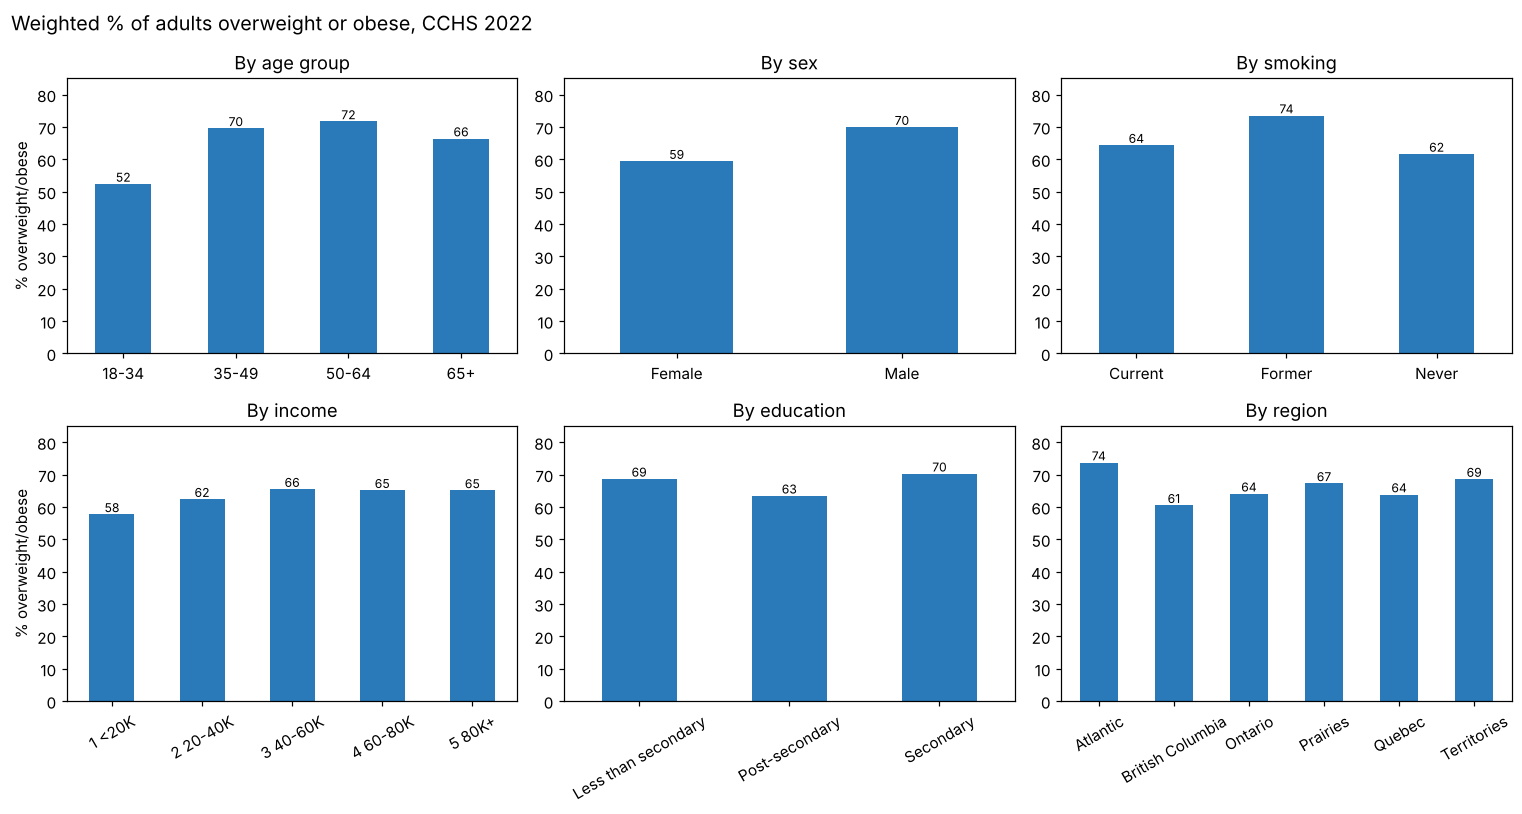

In [3]:
def weighted_share(g):
    return np.average(g["overweight_obese"], weights=g["WTS_M"])

print(f"Unweighted share overweight/obese: {nat['overweight_obese'].mean():.1%}")
print(f"Weighted share (Canadian adults):  {weighted_share(nat):.1%}")

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, var in zip(axes.flat, ["age_group", "sex", "smoking", "income", "education", "region"]):
    s = nat.groupby(var).apply(weighted_share, include_groups=False) * 100
    s.plot.bar(ax=ax, color="#2a7ab9", rot=0 if var in ("sex", "smoking", "age_group") else 30)
    ax.set(title=f"By {var.replace('_', ' ')}", ylabel="% overweight/obese" if ax in axes[:, 0] else "", xlabel="", ylim=(0, 85))
    for i, v in enumerate(s): ax.text(i, v + 0.7, f"{v:.0f}", ha="center", fontsize=8)
fig.suptitle("Weighted % of adults overweight or obese, CCHS 2022", x=0.01, ha="left", fontsize=13)
plt.tight_layout(); plt.savefig("../images/prevalence_by_factor.png", bbox_inches="tight"); plt.show()

## 3. Chi-square tests: is each factor associated with the outcome?
For each factor, the chi-square test of independence asks whether the overweight/obese share differs across its categories more than chance would explain. With ~55,000 people almost everything is "significant", so **Cramér's V** is added to show how *strong* each association is (0 = none, 0.1 = small, 0.3 = medium).

In [4]:
rows = []
for var in covars:
    table = pd.crosstab(nat[var], nat["overweight_obese"])
    chi2, p, dof, _ = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({"factor": var, "chi_square": chi2, "df": dof, "p_value": p, "cramers_v": v})
chi_tbl = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).set_index("factor")
chi_tbl.style.format({"chi_square": "{:.1f}", "p_value": "{:.2g}", "cramers_v": "{:.3f}"})

,chi_square,df,p_value,cramers_v
factor,,,,
age_group,829.2,3,2e-179,0.122
smoking,528.7,2,1.6e-115,0.098
sex,527.9,1,8.2e-117,0.098
region,338.8,5,4.5e-71,0.078
education,115.5,2,8.3e-26,0.046
drinking,47.7,2,4.4e-11,0.029
income,21.4,4,0.00027,0.020


## 4. Multivariable logistic regression (all of Canada)
One model with all factors together, so each odds ratio is **adjusted** for the others. Reference groups: age 18–34, female, never smoked, income under $20K, less than secondary, no drinking in past year, Ontario.
An odds ratio (OR) above 1 means higher odds of overweight/obesity than the reference group. If the 95% CI excludes 1, the association is statistically significant at the 5% level.

In [5]:
formula = ("overweight_obese ~ C(age_group) + C(sex, Treatment('Female')) + C(smoking, Treatment('Never'))"
           " + C(income) + C(education, Treatment('Less than secondary'))"
           " + C(drinking, Treatment('None past year')) + C(region, Treatment('Ontario'))")
model = smf.logit(formula, data=nat).fit(disp=False)

def or_table(m):
    t = pd.DataFrame({"OR": np.exp(m.params), "CI_low": np.exp(m.conf_int()[0]), "CI_high": np.exp(m.conf_int()[1]), "p_value": m.pvalues})
    t = t.drop(index="Intercept")
    t.index = (t.index.str.replace(r"C\((\w+)(, Treatment\('.*?'\))?\)\[T\.", r"\1 = ", regex=True).str.rstrip("]"))
    return t

nat_or = or_table(model)
print(f"n = {int(model.nobs):,}   pseudo R² = {model.prsquared:.3f}")
nat_or.round(3)

n = 55,395   pseudo R² = 0.032


,OR,CI_low,CI_high,p_value
age_group = 35-49,1.837,1.730,1.951,0.000
age_group = 50-64,2.111,1.992,2.238,0.000
age_group = 65+,1.582,1.496,1.673,0.000
sex = Male,1.539,1.483,1.598,0.000
smoking = Current,0.830,0.781,0.882,0.000
smoking = Former,1.419,1.358,1.483,0.000
income = 2 20-40K,1.114,0.993,1.250,0.067
income = 3 40-60K,1.244,1.110,1.395,0.000
income = 4 60-80K,1.249,1.113,1.403,0.000
income = 5 80K+,1.275,1.145,1.420,0.000


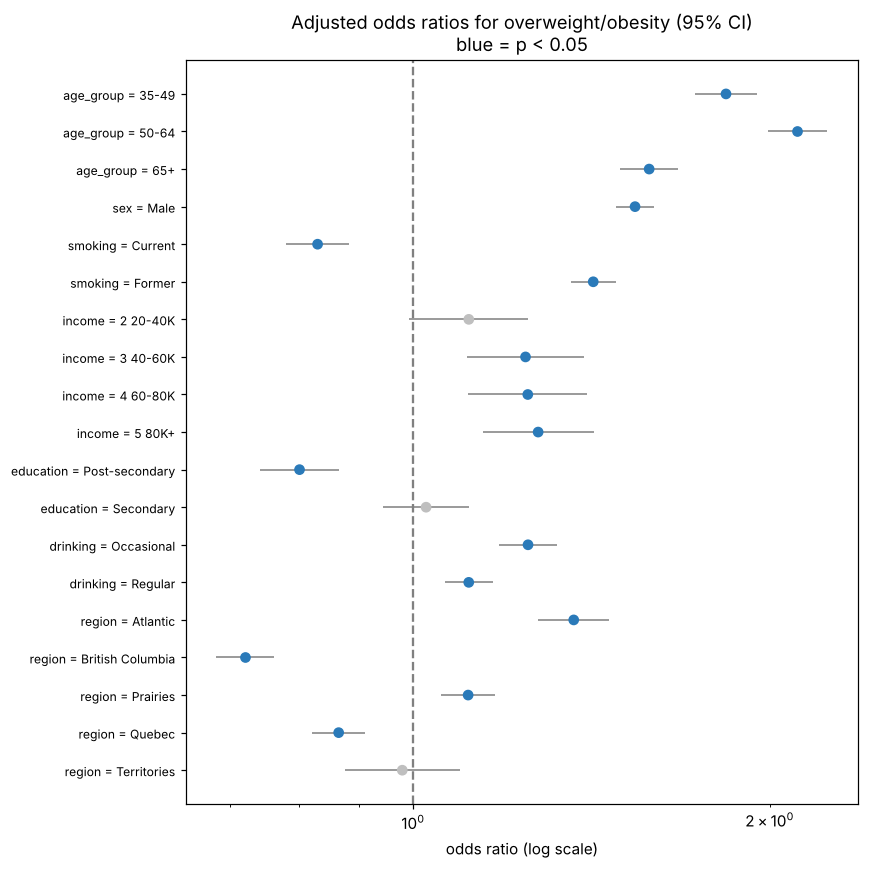

In [6]:
plot = nat_or.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 8))
colors = np.where(plot["p_value"] < 0.05, "#2a7ab9", "#bfbfbf")
ax.errorbar(plot["OR"], range(len(plot)), xerr=[plot["OR"] - plot["CI_low"], plot["CI_high"] - plot["OR"]], fmt="none", ecolor="#7f7f7f", lw=1)
ax.scatter(plot["OR"], range(len(plot)), color=colors, zorder=3)
ax.axvline(1, ls="--", color="grey"); ax.set_xscale("log")
ax.set_yticks(range(len(plot))); ax.set_yticklabels(plot.index, fontsize=8)
ax.set(title="Adjusted odds ratios for overweight/obesity (95% CI)\nblue = p < 0.05", xlabel="odds ratio (log scale)")
plt.tight_layout(); plt.savefig("../images/odds_ratios_national.png", bbox_inches="tight"); plt.show()

## 5. Physical activity and overweight/obesity (territories subsample)
The physical activity module (`PAADVACV`) was answered only by respondents in the territories (Yukon, Northwest Territories, Nunavut) in this file, so the results describe adults in the territories, not all Canadians.

### 5a. 2×2 risk measures: inactive vs active

In [7]:
ter = df.dropna(subset=["overweight_obese", "physical_activity", "age_group", "sex", "smoking", "income"]).copy()
ter["current_smoker"] = (ter["smoking"] == "Current").map({True: "Current", False: "Not current"})
print(f"Territories adults with complete data: {len(ter):,}")
prev = ter.groupby("physical_activity")["overweight_obese"].agg(n="size", cases="sum", pct="mean")
prev = prev.loc[["Active", "Moderately active", "Inactive"]]; prev["pct"] = (prev["pct"] * 100).round(1)
display(prev)

a = ter.query("physical_activity == 'Inactive'")["overweight_obese"]; b = ter.query("physical_activity == 'Active'")["overweight_obese"]
r1, r0 = a.mean(), b.mean()
odds_ratio = (a.sum() * (len(b) - b.sum())) / ((len(a) - a.sum()) * b.sum())
print(f"Risk inactive = {r1:.3f}, risk active = {r0:.3f}")
print(f"Risk difference = {r1 - r0:+.3f}   Relative risk = {r1 / r0:.2f}   Crude odds ratio = {odds_ratio:.2f}")
chi2, p, _, _ = chi2_contingency(pd.crosstab(ter["physical_activity"], ter["overweight_obese"]))
print(f"Chi-square across all 3 activity levels: χ² = {chi2:.2f}, p = {p:.3f}")

Territories adults with complete data: 1,640


,n,cases,pct
physical_activity,,,
Active,1009,662.0,65.6
Moderately active,321,215.0,67.0
Inactive,310,220.0,71.0


Risk inactive = 0.710, risk active = 0.656
Risk difference = +0.054   Relative risk = 1.08   Crude odds ratio = 1.28
Chi-square across all 3 activity levels: χ² = 3.08, p = 0.215


### 5b. Adjusted logistic regression (same model as the STAT 3530 course project)
`overweight_obese ~ physical activity + age group + sex + current smoker + income`

In [8]:
ter_model = smf.logit("overweight_obese ~ C(physical_activity, Treatment('Active')) + C(age_group) + C(sex, Treatment('Female'))"
                      " + C(current_smoker, Treatment('Current')) + C(income)", data=ter).fit(disp=False)
ter_or = or_table(ter_model)
print(f"n = {int(ter_model.nobs):,}")
ter_or.round(3)

n = 1,640


,OR,CI_low,CI_high,p_value
physical_activity = Inactive,1.491,1.113,1.996,0.007
physical_activity = Moderately active,1.172,0.891,1.541,0.257
age_group = 35-49,1.508,1.127,2.018,0.006
age_group = 50-64,1.496,1.113,2.013,0.008
age_group = 65+,1.171,0.861,1.592,0.314
sex = Male,1.045,0.847,1.290,0.681
current_smoker = Not current,1.427,1.125,1.810,0.003
income = 2 20-40K,1.249,0.785,1.989,0.348
income = 3 40-60K,1.233,0.782,1.946,0.367
income = 4 60-80K,1.326,0.811,2.169,0.261


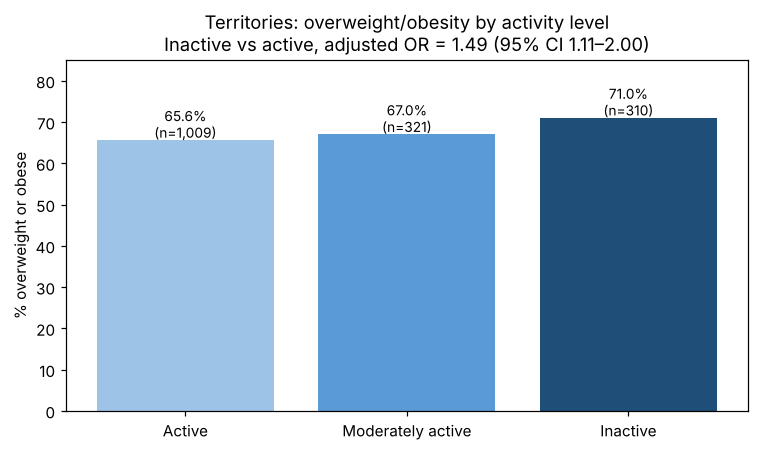

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.2))
bars = ax.bar(prev.index, prev["pct"], color=["#9dc3e6", "#5b9bd5", "#1f4e79"])
for bar, (_, r) in zip(bars, prev.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, r["pct"] + 0.6, f"{r['pct']:.1f}%\n(n={int(r['n']):,})", ha="center", fontsize=9)
pa_or = ter_or.loc["physical_activity = Inactive"]
ax.set(ylim=(0, 85), ylabel="% overweight or obese",
       title=f"Territories: overweight/obesity by activity level\nInactive vs active, adjusted OR = {pa_or['OR']:.2f} (95% CI {pa_or['CI_low']:.2f}–{pa_or['CI_high']:.2f})")
plt.tight_layout(); plt.savefig("../images/activity_territories.png", bbox_inches="tight"); plt.show()

## 6. Findings
Numbers come from the tables above (OR = adjusted odds ratio).

**All of Canada (n = 55,395 adults)**
- **64.7%** of Canadian adults are overweight or obese (survey-weighted).
- **Age:** odds peak at 50–64 (OR 2.11 vs 18–34) and ease slightly after 65 (OR 1.58).
- **Sex:** men have 54% higher odds than women (OR 1.54).
- **Smoking:** former smokers have higher odds than never smokers (OR 1.42), likely weight gained after quitting; current smokers have lower odds (OR 0.83), consistent with nicotine suppressing appetite. This is not a health benefit of smoking.
- **Education:** post-secondary graduates have 20% lower odds than people without a secondary diploma (OR 0.80).
- **Income:** higher household income goes with slightly *higher* odds (OR 1.28 for $80K+ vs under $20K).
- **Region:** compared with Ontario, odds are higher in the Atlantic provinces (OR 1.37) and the Prairies (OR 1.11), and lower in British Columbia (OR 0.72) and Quebec (OR 0.87).
- Each factor's effect is modest on its own (pseudo R² = 0.03): weight depends on many things this survey does not measure, such as diet and genetics.

**Territories (physical activity, n = 1,640)**
- Overweight/obesity rises from **65.6%** of active adults to **67.0%** of moderately active and **71.0%** of inactive adults.
- Unadjusted, the difference is not significant (χ² p = 0.22). After adjusting for age, sex, smoking and income, **inactive adults have 1.49 times the odds** of active adults (95% CI 1.11–2.00, p = 0.007). Adjustment matters here because the groups differ in age and smoking.
- Moderately active adults do not differ significantly from active adults (OR 1.17, p = 0.26).

## 7. Limitations
- **Cross-sectional:** associations only, no cause and effect (weight can also reduce activity).
- **Self-reported height and weight** usually underestimate BMI.
- **Weights:** prevalence uses survey weights; the regressions are unweighted and the PUMF has no bootstrap weights, so confidence intervals are approximate.
- **Physical activity** was only available for the territories subsample, so section 5 cannot be generalised to all Canadians.
- **Outcome** combines overweight and obese (the PUMF groups them), so this is not obesity alone.

In [10]:
nat_or.round(4).to_csv("../images/odds_ratios_national.csv")
ter_or.round(4).to_csv("../images/odds_ratios_territories.csv")
chi_tbl.round(4).to_csv("../images/chi_square_tests.csv")